## Classification and Logistic Regression

*Note: The code in this notebook was generated with the assistance of Claude.*

I will be adding to this notebook throughout the week! 

In [1]:
import numpy as np

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_predict, cross_validate
from sklearn.calibration import CalibrationDisplay
from sklearn.metrics import log_loss, accuracy_score, confusion_matrix, ConfusionMatrixDisplay, roc_auc_score, precision_score, recall_score, RocCurveDisplay

In [2]:
# This dataset can be used to predict whether a patient has a 10-year risk of future CHD (coronary heart disease)
fram = pd.read_csv("../data/framingham.csv")
fram.head()

,male,age,education,currentSmoker,cigsPerDay,BPMeds,prevalentStroke,prevalentHyp,diabetes,totChol,sysBP,diaBP,BMI,heartRate,glucose,TenYearCHD
0,1,39,4.0,0,0.0,0.0,0,0,0,195.0,106.0,70.0,26.97,80.0,77.0,0
1,0,46,2.0,0,0.0,0.0,0,0,0,250.0,121.0,81.0,28.73,95.0,76.0,0
2,1,48,1.0,1,20.0,0.0,0,0,0,245.0,127.5,80.0,25.34,75.0,70.0,0
3,0,61,3.0,1,30.0,0.0,0,1,0,225.0,150.0,95.0,28.58,65.0,103.0,1
4,0,46,3.0,1,23.0,0.0,0,0,0,285.0,130.0,84.0,23.10,85.0,85.0,0


In [3]:
# Do we have any missing data? 
fram.isna().sum()

male                 0
age                  0
education          105
currentSmoker        0
cigsPerDay          29
BPMeds              53
prevalentStroke      0
prevalentHyp         0
diabetes             0
totChol             50
sysBP                0
diaBP                0
BMI                 19
heartRate            1
glucose            388
TenYearCHD           0
dtype: int64

In [4]:
# For simplicity, we'll drop rows with any missing values (about 14% of rows)
# We will come back to this dataset to look more at imputation
# For now, we are going to just use rows that have all the data
fram = fram.dropna()
fram.shape

(3658, 16)

In [5]:
# What fraction of people developed coronary heart disease (CHD) within 10 years?
fram['TenYearCHD'].value_counts(normalize=True)

TenYearCHD
0    0.847731
1    0.152269
Name: proportion, dtype: float64

In [6]:
# We want to predict whether or not someone develops CHD within 10 years (1 or 0) based on a variety of risk factors
y = fram['TenYearCHD']

# There are three different types of variables in this dataset:
# - education is categorical (levels 1-4), so we one-hot encode it
# - binary variables are already 0/1, so we leave them alone
# - numeric variables
cats = ["education"]
bins = ["male", "currentSmoker", "BPMeds", "prevalentStroke", "prevalentHyp", "diabetes"]
nums = ["age", "cigsPerDay", "totChol", "sysBP", "diaBP", "BMI", "heartRate", "glucose"]

# Note: For this first pass, we going to use
# All of the numeric veriables
# Only a single categorical variable (Male or female)
male = ["male"]
X = fram[male + nums]

In [7]:
# Let's build a logistic regression model
# Note: We are NOT going to scale anything for this first go around, to demonstrate why scaling is important
# This is problematic and in practice, we would scale everything first. 

logreg = LogisticRegression().fit(X,y)

/opt/anaconda3/envs/ds6021/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [8]:
# We'll come back to the warning later. 
# Let's look at predicted vs actual CHD, and look at the confusion matrix

p = logreg.predict_proba(X)
#p = logreg.predict(X)
p

array([[0.90254648, 0.09745352],
       [0.96403579, 0.03596421],
       [0.81398089, 0.18601911],
       ...,
       [0.87277326, 0.12722674],
       [0.84061561, 0.15938439],
       [0.897339  , 0.102661  ]], shape=(3658, 2))

In [9]:
# Note that this returns probability estimates for 0 or 1, and if we add each pair it should sum to 1. 
# We can look at just the second column (prediction of CHD) and get information about both

p = logreg.predict_proba(X)[:, 1] # second column
y_hat = (p >=0.5).astype(int) # if p >= 0.5, set to 1 (we can vary this threshold!)

In [10]:
# Now let's create a dataframe of actual vs predicted
results = pd.DataFrame(
    {
    "Actual_CHD": y,
    "Predicted_prob_CHD": p.round(3),
    "Predicted_label": y_hat
})

results

,Actual_CHD,Predicted_prob_CHD,Predicted_label
0,0,0.097,0
1,0,0.036,0
2,0,0.186,0
3,1,0.209,0
4,0,0.084,0
...,...,...,...
4233,1,0.418,0
4234,0,0.360,0
4237,0,0.127,0
4238,0,0.159,0


In [11]:
# Now we look at the confusion matrix, which gives us the following information:
# [[True Negative, False Positive],[False Negative, True Positive]]

confusion_matrix(y, y_hat)

array([[3089,   12],
       [ 538,   19]])

In [12]:
# We can put this in a slightly more digestible form
tn, fp, fn, tp = confusion_matrix(y, y_hat).ravel().tolist()
tn, fp, fn, tp

(3089, 12, 538, 19)

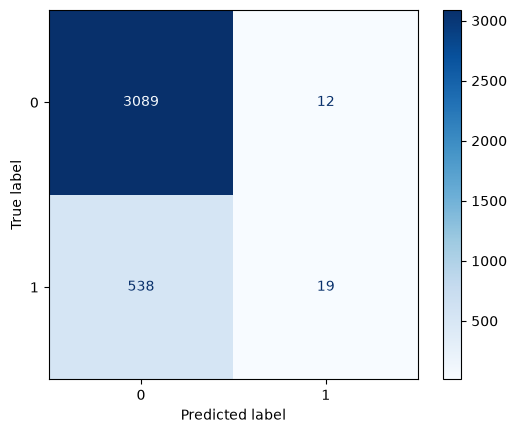

In [13]:
# We can also plot the confusion matrix to visualize this. 
cm = confusion_matrix(y, y_hat, labels=logreg.classes_)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=logreg.classes_)
disp.plot(cmap="Blues")
plt.show()

count    538.000000
mean       0.197589
std        0.104243
min        0.017000
25%        0.117000
50%        0.174000
75%        0.265000
max        0.497000
Name: Predicted_prob_CHD, dtype: float64


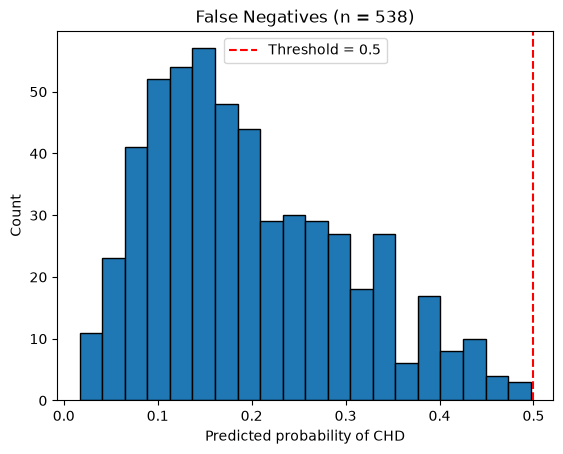

In [14]:
# The results above show a lot of false negatives (e.g. the true label is 1, but the predicted label is 0)
fn_results = results[(results["Actual_CHD"] == 1) & (results["Predicted_label"] == 0)]

print(fn_results["Predicted_prob_CHD"].describe())

plt.hist(fn_results["Predicted_prob_CHD"], bins=20, edgecolor="black")
plt.axvline(0.5, color="red", linestyle="--", label="Threshold = 0.5")
plt.xlabel("Predicted probability of CHD")
plt.ylabel("Count")
plt.title(f"False Negatives (n = {len(fn_results)})")
plt.legend()
plt.show()

In [15]:

# What happens to our confusion matrix if we lower the threshold to 0.2?
y_hat_alt = (p >=0.2).astype(int)
confusion_matrix(y, y_hat_alt)

array([[2406,  695],
       [ 312,  245]])

In [16]:
# We can also normalize
confusion_matrix(y, y_hat_alt, normalize="true")

array([[0.77587875, 0.22412125],
       [0.56014363, 0.43985637]])

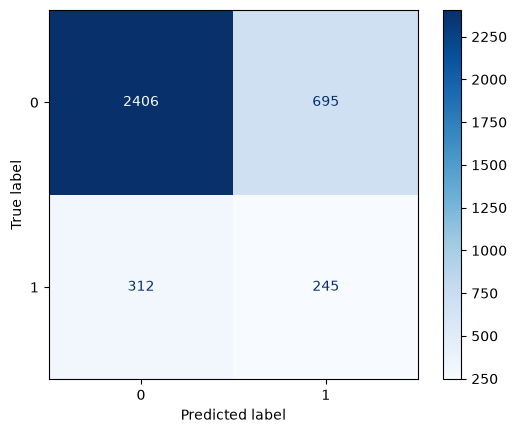

In [17]:
# What does changing the threshold tell us about the tradeoff between false negatives and false positives? 
cm = confusion_matrix(y, y_hat_alt, labels=logreg.classes_)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=logreg.classes_)
disp.plot(cmap="Blues")
plt.show()

In the example above, we are trading off false negatives for false positives. Let's see if scaling the numeric variables gives us a better answer. 

In [18]:
# First, let's look at the scale of the numeric variables.
fram.describe()


,male,age,education,currentSmoker,cigsPerDay,BPMeds,prevalentStroke,prevalentHyp,diabetes,totChol,sysBP,diaBP,BMI,heartRate,glucose,TenYearCHD
count,3658.000000,3658.000000,3658.000000,3658.000000,3658.000000,3658.000000,3658.000000,3658.000000,3658.000000,3658.000000,3658.000000,3658.000000,3658.000000,3658.000000,3658.000000,3658.000000
mean,0.443685,49.551941,1.980317,0.489065,9.025424,0.030344,0.005741,0.311646,0.027064,236.847731,132.370558,82.917031,25.782802,75.730727,81.852925,0.152269
std,0.496886,8.562029,1.022656,0.499949,11.921590,0.171557,0.075561,0.463229,0.162292,44.097681,22.086866,11.974258,4.065601,11.981525,23.904164,0.359331
min,0.000000,32.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,113.000000,83.500000,48.000000,15.540000,44.000000,40.000000,0.000000
25%,0.000000,42.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,206.000000,117.000000,75.000000,23.080000,68.000000,71.000000,0.000000
50%,0.000000,49.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,234.000000,128.000000,82.000000,25.380000,75.000000,78.000000,0.000000
75%,1.000000,56.000000,3.000000,1.000000,20.000000,0.000000,0.000000,1.000000,0.000000,263.000000,143.875000,90.000000,28.037500,82.000000,87.000000,0.000000
max,1.000000,70.000000,4.000000,1.000000,70.000000,1.000000,1.000000,1.000000,1.000000,600.000000,295.000000,142.500000,56.800000,143.000000,394.000000,1.000000


In [19]:
## There is a fair bit of variability in the numeric variables so let's scale them
# We are going to look at two different preprocessors:
# First, we will use the standard scaler only on the numeric variables, passing through the categorical
# Second, we will use the standard scaler on ALL variables

# Remember that Logistic regression does regularization by default, which depends on scaling, even for categorical variables

# Option 1: pass "male" through unchanged (it's already 0/1), scale only the numeric variables
preprocess_pass = ColumnTransformer(transformers=[
    ("binary", "passthrough", male),
    ("numeric", StandardScaler(), nums)
])

# Option 2: scale everything, including the 0/1 "male" variable
preprocess_all = ColumnTransformer(transformers=[
    ("all", StandardScaler(), male + nums)
])

pipe_pass = Pipeline(steps=[
    ("preprocess", preprocess_pass),
    ("model", LogisticRegression())  
])

pipe_all = Pipeline(steps=[
    ("preprocess", preprocess_all),
    ("model", LogisticRegression())  
])

# Note that we are using the X and y that we defined above
pipe_pass.fit(X, y)
pipe_all.fit(X, y)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocess', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](9,)","['male','age','cigsPerDay',...,'BMI','heartRate','glucose']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,9
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('all', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not

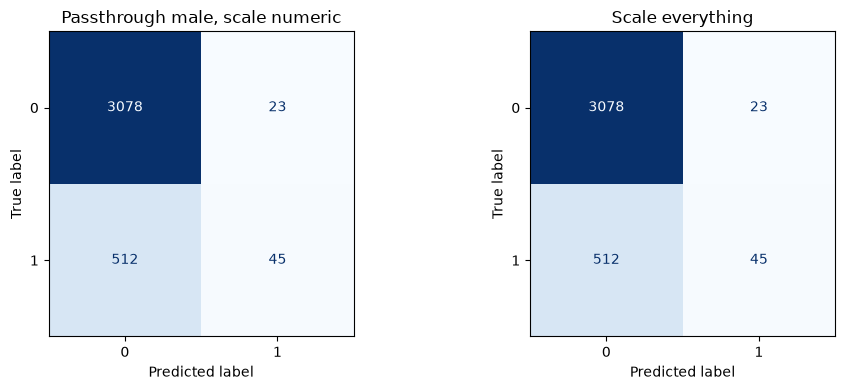

In [20]:
# Now let's compare the confusion matrices for these side by side

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for ax, pipe, title in zip(axes,
                           [pipe_pass, pipe_all],
                           ["Passthrough male, scale numeric", "Scale everything"]):
    y_hat_pipe = pipe.predict(X)
    cm = confusion_matrix(y, y_hat_pipe, labels=pipe.classes_)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=pipe.classes_)
    disp.plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(title)

plt.tight_layout()
plt.show()

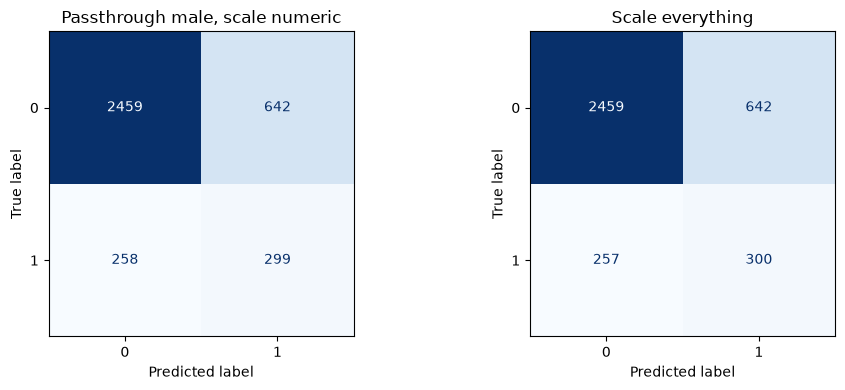

In [21]:
# What if we adjust the threshold to be 0.2 instead of 0.5? 
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for ax, pipe, title in zip(axes,
                           [pipe_pass, pipe_all],
                           ["Passthrough male, scale numeric", "Scale everything"]):
    y_hat_pipe = (pipe.predict_proba(X)[:, 1] >= 0.2).astype(int)
    cm = confusion_matrix(y, y_hat_pipe, labels=pipe.classes_)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=pipe.classes_)
    disp.plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(title)

plt.tight_layout()
plt.show()

In [22]:
for name, pipe in [("pass", pipe_pass), ("all", pipe_all)]:
    model = pipe.named_steps["model"]
    feat_names = pipe.named_steps["preprocess"].get_feature_names_out()
    coefs = pd.Series(model.coef_.ravel(), index=feat_names)
    print(f"--- {name} --- intercept: {model.intercept_[0]:.4f}")
    print(coefs)

--- pass --- intercept: -2.2306
binary__male           0.548228
numeric__age           0.556676
numeric__cigsPerDay    0.235793
numeric__totChol       0.101400
numeric__sysBP         0.409831
numeric__diaBP        -0.034989
numeric__BMI           0.040023
numeric__heartRate    -0.035746
numeric__glucose       0.173695
dtype: float64
--- all --- intercept: -1.9880
all__male          0.275221
all__age           0.556733
all__cigsPerDay    0.235904
all__totChol       0.101930
all__sysBP         0.410598
all__diaBP        -0.036279
all__BMI           0.039694
all__heartRate    -0.035602
all__glucose       0.173818
dtype: float64


In [ ]:
# Now let's look at the coefficients and odds ratios for the model where we did not scale the male/female feature

model = pipe_pass.named_steps["model"]
feat_names = pipe_pass.named_steps["preprocess"].get_feature_names_out()

coef_table = pd.DataFrame({
    "coefficient": model.coef_[0],
    "odds_ratio": np.exp(model.coef_[0]),
}, index=feat_names)

coef_table.sort_values("odds_ratio", ascending=False).round(3)

Some comments on the coefficients and odds ratios presented above:

* **Male/Female difference**: Remember, since we did not scale this variable, we can interpret female as the reference level and the odds ratio as follows: Holding all other variables constant, males have about 1.73 times the odds of developing CHD within 10 years compared with women. Their odds are about 73% higher. Note: We would NOT read this as "1.73 times as likely". 

* **Heart rate**: Holding all other variables constant, each 1 standard deviation increase in heart rate multiplies the odds of CHD by about 0.965, which means the odds are about 3.5% lower. Because the odds ratio is so close to one, we would read this as "no clear effect" as opposed to "a protective effect" 

In [ ]:
# Base log loss: predict the overall CHD rate for everyone (no predictors)
base_rate = y.mean()
ll_base = log_loss(y, np.full(len(y), base_rate))
ll_model = log_loss(y, pipe_pass.predict_proba(X)[:, 1])

print(f"Base rate:                 {base_rate:.4f}")
print(f"Log odds of base rate:     {np.log(base_rate / (1 - base_rate)):.4f}")
print(f"Base log loss:             {ll_base:.4f}")
print(f"Model log loss:            {ll_model:.4f}")

# The model's intercept: log odds for a woman (male=0) with every numeric variable at its mean (scaled value 0)
b0 = model.intercept_[0]
print(f"Model intercept:           {b0:.4f}")
print(f"Intercept as probability:  {1 / (1 + np.exp(-b0)):.4f}")

Some comments on the base log loss and intercept, above:

* The base rate is about 15% of folks will develop CHD (which we saw above)
* The model log loss is LOWER than the base log loss which is good. 
* How to think about the intercept:
    * It is lower than the log odds of the base rate.
    * The intercept is the baseline for one specific group: women of average age, blood pressure, etc.
    * Being make or above average in other variables (age, bloog pressure, etc) adds log odds on top of this. 

In [ ]:
# Each person's log loss and contribution to log loss

contrib = X.copy()
contrib["TenYearCHD"] = y

# decision_function gives the log odds: intercept + sum(beta * x)
contrib["log_odds"] = pipe_pass.decision_function(X)
contrib["p_hat"] = 1 / (1 + np.exp(-contrib["log_odds"]))
contrib["loss"] = -(y * np.log(contrib["p_hat"]) + (1 - y) * np.log(1 - contrib["p_hat"]))

# Sanity check: the mean of the individual losses is the log loss
print(np.isclose(contrib["loss"].mean(), ll_model))

In [ ]:
# 10 largest contributions to log loss
contrib.sort_values("loss", ascending=False).head(10).round(3)

In [ ]:
# 10 smallest contributions to log loss
contrib.sort_values("loss").head(10).round(3)

Comments on the smallest and largest contributions to the log loss:
* The largest contributions are young women (35-44) who did develop CHD, but the model gave them very low probabilities (0.015 to 0.039) of developing CHD
* The smallest contributions are women between 33-38 who did not develop CHD. The probabilities are very similar, but the contributions to the loss are much lower. 

This is a case where we would want to investigate where there is information we are missing that would identify these women. In general, young women rarely develop CHD within 10 years, so the fact that the model predcits them as zeros makes sense. This is an example of log loss penalizing confident mistakes.  

In [ ]:
# Now, let's look at accuracy/precision/recall and the auc score  
# We will define a function so we can do this repeatedly

def get_metrics(y_true, p, threshold=0.5):
    y_pred = (p >= threshold).astype(int)
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred),
        "recall": recall_score(y_true, y_pred),
        "AUC": roc_auc_score(y_true, p),  # AUC uses probabilities, not labels
    }

p_in = pipe_all.predict_proba(X)[:, 1]
get_metrics(y, p_in)

{'accuracy': 0.8537452159650082,
 'precision': 0.6617647058823529,
 'recall': 0.0807899461400359,
 'AUC': 0.736928552033658}

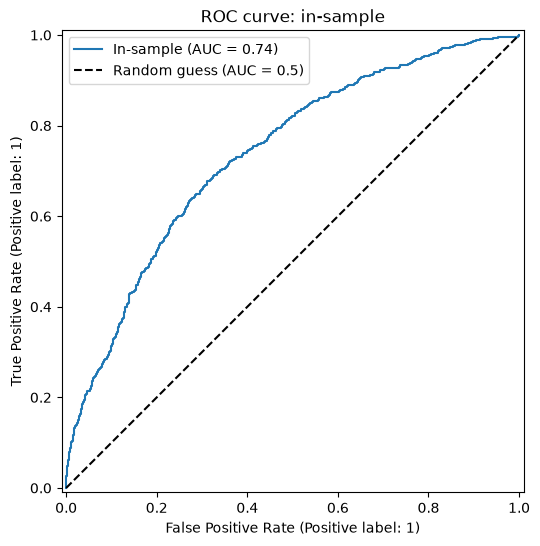

In [24]:
# We can also plot the ROC curve
fig, ax = plt.subplots(figsize=(6, 6))
RocCurveDisplay.from_predictions(y, p_in, name="In-sample", ax=ax)
ax.plot([0, 1], [0, 1], "k--", label="Random guess (AUC = 0.5)")
ax.set_title("ROC curve: in-sample")
ax.legend()
plt.show()


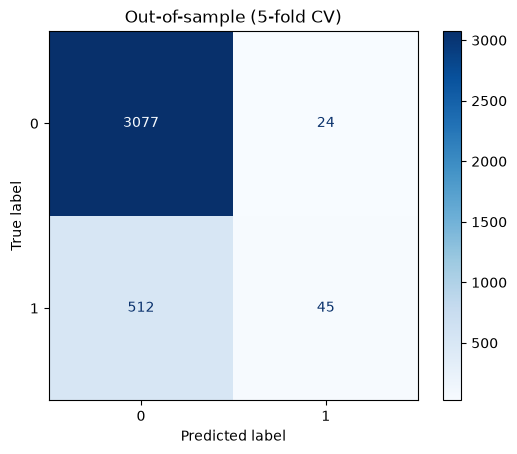

In [25]:
# Now let's repeat all of this using cross-validation
# NOTE: We need to use Stratified KFold here in order to preserve the class balance in each set 

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
p_cv = cross_val_predict(pipe_all, X, y, cv=cv, method="predict_proba")[:, 1]

y_hat_cv = (p_cv >= 0.5).astype(int)
cm = confusion_matrix(y, y_hat_cv)
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=[0, 1]).plot(cmap="Blues")
plt.title("Out-of-sample (5-fold CV)")
plt.show()

In [26]:
# We can also look at mean accuracy/precision/recall/and AUC from the cross validation
# Recall for linear regression we looked at RMSE like this:
# score = -cross_val_score(pipe, X, y, cv=cv, n_jobs=-1, scoring="neg_root_mean_squared_error").mean()
# Here we are using cross_validate instead because it allows us to calculate multiple metrics at once

scoring_metrics = ["accuracy", "precision", "recall", "roc_auc"]

# Run multi-metric cross-validation
cv_results = cross_validate(
    pipe_all, X, y, cv=cv, scoring=scoring_metrics, return_train_score=False
)

# Print the mean performance across all folds
print(f"Mean Accuracy:  {cv_results['test_accuracy'].mean():.4f}")
print(f"Mean Precision: {cv_results['test_precision'].mean():.4f}")
print(f"Mean Recall:    {cv_results['test_recall'].mean():.4f}")
print(f"Mean ROC-AUC:   {cv_results['test_roc_auc'].mean():.4f}")

Mean Accuracy:  0.8535
Mean Precision: 0.6486
Mean Recall:    0.0808
Mean ROC-AUC:   0.7299


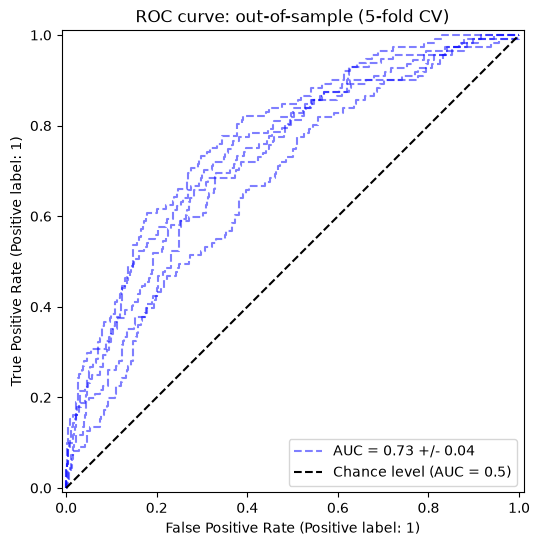

In [27]:
# ROC Curve
cv_results = cross_validate(pipe_all, X, y, cv=cv,
                            return_estimator=True, return_indices=True)

fig, ax = plt.subplots(figsize=(6, 6))
RocCurveDisplay.from_cv_results(cv_results, X, y, ax=ax, plot_chance_level=True)
ax.set_title("ROC curve: out-of-sample (5-fold CV)")
plt.show()
